# `/recommend` — modélisation du classement des cultures

Second moteur, et le seul des deux où il y a réellement quelque chose à modéliser.

Le notebook 07 a montré que le jeu simulé **ne distingue pas les cultures** : à conditions
égales, les six donnent le même rendement à 0,03 t/ha près. Classer des cultures à partir de
ce jeu reviendrait à les ordonner au hasard. `/recommend` s'appuie donc sur le **jeu FAO
reconstruit** à l'étape 1, où la culture explique réellement le rendement.

Ce notebook commence par un piège de méthode qui, s'il n'était pas traité, ferait annoncer
une performance quatre à cinq fois supérieure à la réalité.

# Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (ExtraTreesRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

sys.path.insert(0, str(Path.cwd().parent))

from src import config, tracking, utils
from src.models import evaluation, features, historique, protocole
from src.models import recommend_model as rm

utils.style()
np.random.seed(config.SEED)
tracking.configure(tracking.EXPERIENCE_RECOMMEND)

2026/10/09 16:09:10 INFO mlflow.tracking.fluent: Experiment with name 'agritech-recommend' does not exist. Creating a new experiment.


# Données et variables dérivées

In [2]:
brut = pd.read_csv(config.CROP_YIELD_PREDICTION_CSV)
prepare = historique.prepare(brut)

# Protocol safeguard: the history must contain no information from the current year.
historique.controle_absence_de_fuite(prepare)
print("contrôle d'absence de fuite temporelle : OK")

df = prepare.dropna(subset=rm.VARIABLES + [features.CIBLE_RECOMMEND]).reset_index(drop=True)
print(f"\nlignes exploitables : {len(df):,} ({df.iso3.nunique()} pays, "
      f"{df.crop.nunique()} cultures, {df.year.min()}-{df.year.max()})")
print(f"lignes écartées     : {len(prepare) - len(df):,} — première année de chaque pays "
      "(sans historique) ou variable manquante")
df[rm.VARIABLES].describe().T.round(2)

contrôle d'absence de fuite temporelle : OK

lignes exploitables : 15,605 (117 pays, 10 cultures, 1991-2013)
lignes écartées     : 9,922 — première année de chaque pays (sans historique) ou variable manquante


,count,mean,std,min,25%,50%,75%,max
rain_mm,15605.0,1152.24,718.75,51.00,619.00,1083.00,1646.00,3240.00
year,15605.0,2002.16,6.59,1991.00,1996.00,2002.00,2008.00,2013.00
temp_hist,15605.0,19.51,6.88,2.57,14.69,20.47,25.96,30.25
log_pest_hist,15605.0,7.50,2.76,0.04,5.47,7.85,9.56,14.39
lat_abs,15605.0,24.26,16.03,0.55,11.91,19.14,38.76,61.40
geo_x,15605.0,0.47,0.43,-0.83,0.23,0.61,0.80,0.99
geo_y,15605.0,0.08,0.61,-0.98,-0.27,0.22,0.55,0.98
geo_z,15605.0,0.25,0.39,-0.63,-0.03,0.26,0.59,0.88


**Les variables construites, et pourquoi chacune existe :**

| Variable | Calcul | Raison |
|---|---|---|
| `temp_hist`, `log_pest_hist` | moyenne des 3 années précédentes du pays | **les conditions de l'année à venir sont inconnues au moment de recommander** : on ne peut pas donner au modèle la météo qu'il doit anticiper |
| `log_pesticides` | `log1p` du tonnage | l'échelle couvre 7 ordres de grandeur ; en brut, presque toutes les lignes se tassent en bas |
| `lat_abs` | latitude sans signe | distance à l'équateur : un pays à −40° et un pays à +40° ont des climats comparables, ce que la latitude signée ne dit pas |
| `geo_x`, `geo_y`, `geo_z` | position sur la sphère unité | situe le pays **sans lui donner d'identifiant** ; deux voisins restent proches, y compris de part et d'autre du méridien ±180° |

Les retards sont obtenus en décalant la table pays-année puis en joignant sur
`(iso3, year)`, et non avec `shift()` : une année absente reste absente, au lieu d'être
remplacée par la précédente. Le contrôle ci-dessus recalcule l'historique attendu et
compare — il échoue si la moindre information du futur s'est glissée dedans.

# 1. Le piège : pourquoi un découpage aléatoire mentirait

Le rendement d'un couple pays × culture change peu d'une année sur l'autre. Un découpage
aléatoire placerait donc des lignes **quasi identiques** dans l'apprentissage et dans
l'évaluation : le modèle n'aurait plus qu'à reconnaître le pays pour retrouver la réponse.

In [3]:
pivot = df.pivot_table(index=["iso3", "crop"], columns="year", values="yield_t_ha")
correlations = [
    pivot[annee].corr(pivot[annee + 1])
    for annee in range(int(df.year.min()), int(df.year.max()))
    if annee in pivot and annee + 1 in pivot
]
print(f"corrélation du rendement avec l'année précédente : {np.nanmean(correlations):.4f}")

corrélation du rendement avec l'année précédente : 0.9850


In [4]:
# The same model, evaluated in two ways.
X, y = df[rm.VARIABLES], df[features.CIBLE_RECOMMEND]

appr, test = train_test_split(np.arange(len(df)), test_size=0.25, random_state=config.SEED)
modele = rm.pipeline(ExtraTreesRegressor(n_estimators=150, random_state=config.SEED, n_jobs=1))
aleatoire = modele.fit(X.iloc[appr], y.iloc[appr])
score_aleatoire = evaluation.metriques(y.iloc[test], aleatoire.predict(X.iloc[test]))

X_app, X_test, y_app, y_test = protocole.decoupage_temporel(
    df, rm.VARIABLES, features.CIBLE_RECOMMEND)
temporel = rm.pipeline(
    ExtraTreesRegressor(n_estimators=150, random_state=config.SEED, n_jobs=1)
).fit(X_app, y_app)
score_temporel = evaluation.metriques(y_test, temporel.predict(X_test))

pd.DataFrame({
    "découpage aléatoire": [score_aleatoire["test_rmse"], score_aleatoire["test_r2"]],
    "découpage temporel": [score_temporel["test_rmse"], score_temporel["test_r2"]],
}, index=["RMSE (t/ha)", "R²"]).round(4)

,découpage aléatoire,découpage temporel
RMSE (t/ha),1.1871,1.7598
R²,0.9741,0.9594


**Observations — l'écart est considérable :**

- Le rendement est corrélé à **0,985** avec celui de l'année précédente.
- Évalué par découpage aléatoire, le modèle affiche une RMSE flatteuse ; évalué en prédisant
  une année qu'il n'a jamais vue, son erreur est **nettement plus élevée**.
- La première mesure n'est pas une performance, c'est une **fuite** : des lignes presque
  identiques se trouvaient des deux côtés.

> **Tout le reste du notebook utilise le découpage temporel.** 2013 est réservée au test
> final et ne sera touchée qu'une seule fois, à la fin.

In [5]:
plis = protocole.cv_temporelle(df["year"], rm.ANNEES_VALIDATION)
protocole.resume_plis(plis, rm.ANNEES_VALIDATION)

,annee validee,lignes d'apprentissage,lignes evaluees
0,2008,11443,692
1,2009,12135,690
2,2010,12825,693
3,2011,13518,693
4,2012,14211,694


**Lecture :** chaque année de validation est prédite par un modèle appris sur **toutes les
années qui la précèdent**, et sur elles seules. Le jeu d'apprentissage grandit d'un pli au
suivant : c'est exactement la situation du service, qui disposera chaque année d'une saison
de plus.

Les plis ne couvrent volontairement pas toutes les lignes — seules les cinq dernières années
sont évaluées. C'est pourquoi les prédictions hors apprentissage passent par
`evaluation.predictions_hors_apprentissage` et non par `cross_val_predict`, qui exigerait
une couverture complète.

# 2. Faut-il donner le pays au modèle ?

Avant de construire quoi que ce soit, on mesure l'apport de `iso3` et de `year`. C'est ce
qui permet d'affirmer, **mesure en main**, que le modèle final ne reçoit pas d'identifiant
de pays.

In [6]:
def evalue(nom, variables, modele, etape, note):
    plis_resultat = evaluation.validation_par_pli(
        rm.pipeline(modele, variables), df[variables], df[features.CIBLE_RECOMMEND], plis)
    metriques = evaluation.resume(plis_resultat)
    tracking.journalise(
        nom,
        {"modele": type(modele).__name__, "feature_set": nom, "protocole": "temporel",
         "n_variables": len(variables)},
        metriques, etape=etape, note=note)
    return plis_resultat


base = {}
for nom in ("conditions", "conditions_annee", "conditions_pays", "conditions_pays_annee"):
    variables = features.RECOMMEND_JEUX[nom]
    base[nom] = evalue(
        nom, variables, Ridge(), "ablation",
        f"Apport de iso3 et year, mesuré avant toute construction de variable.")
    print(f"  {nom:26} {evaluation.ligne_lisible(evaluation.resume(base[nom]))}")

  conditions                 RMSE 5.5818 ± 0.1154 t/ha | MAE 3.3998 t/ha | R² 0.5646
  conditions_annee           RMSE 5.4928 ± 0.1068 t/ha | MAE 3.4556 t/ha | R² 0.5783


  conditions_pays            RMSE 4.6197 ± 0.1258 t/ha | MAE 3.0728 t/ha | R² 0.7018


  conditions_pays_annee      RMSE 4.5168 ± 0.1160 t/ha | MAE 3.0076 t/ha | R² 0.7149


In [7]:
evaluation.compare_appariee(base, reference="conditions",
                            libelles=rm.ANNEES_VALIDATION).round(4)

,RMSE,MAE,R2,ecart a la reference,plis ameliores,2008,2009,2010,2011,2012
conditions,5.5818,3.3998,0.5646,0.0000,0/5,5.4267,5.7050,5.4651,5.6926,5.6196
conditions_annee,5.4928,3.4556,0.5783,-0.0890,5/5,5.3536,5.6172,5.3824,5.5886,5.5222
conditions_pays,4.6197,3.0728,0.7018,-0.9621,5/5,4.4056,4.6943,4.5489,4.7428,4.7069
conditions_pays_annee,4.5168,3.0076,0.7149,-1.0650,5/5,4.3130,4.5865,4.4628,4.6233,4.5981


**Observations :**

- **`year` apporte beaucoup** : la retirer dégrade nettement l'erreur. Ce n'est pas une
  variable accessoire — elle porte la tendance technologique, le rendement mondial
  progressant régulièrement sur la période.
- **`iso3` apporte aussi**, ce qui est attendu : le pays résume à lui seul le niveau de
  développement agricole, les variétés, la mécanisation. Mais c'est précisément l'information
  qu'un agriculteur ne peut pas « saisir », et qui empêcherait le modèle de généraliser à un
  pays absent du jeu.
- La suite remplace donc le code pays par la **position géographique** : elle porte une
  partie de la même information, mais de façon continue et partagée entre voisins.

# 3. Construction des variables : que gagne-t-on ?

In [8]:
etapes = {}
for nom in ("conditions_annee", "log_pesticides", "geographie", "historique"):
    variables = features.RECOMMEND_JEUX[nom]
    etapes[nom] = evalue(
        nom, variables, Ridge(), "ablation",
        "Construction progressive de la représentation, régression linéaire.")
    print(f"  {nom:22} {len(variables):2d} variables  "
          f"{evaluation.ligne_lisible(evaluation.resume(etapes[nom]))}")

  conditions_annee        5 variables  RMSE 5.4928 ± 0.1068 t/ha | MAE 3.4556 t/ha | R² 0.5783
  log_pesticides          5 variables  RMSE 5.3390 ± 0.0927 t/ha | MAE 3.3694 t/ha | R² 0.6016


  geographie              9 variables  RMSE 5.1513 ± 0.0907 t/ha | MAE 3.3425 t/ha | R² 0.6291
  historique              9 variables  RMSE 5.1426 ± 0.1000 t/ha | MAE 3.3390 t/ha | R² 0.6304


In [9]:
evaluation.compare_appariee(etapes, reference="conditions_annee").round(4)

,RMSE,MAE,R2,ecart a la reference,plis ameliores
conditions_annee,5.4928,3.4556,0.5783,0.0000,0/5
log_pesticides,5.3390,3.3694,0.6016,-0.1538,5/5
geographie,5.1513,3.3425,0.6291,-0.3415,5/5
historique,5.1426,3.3390,0.6304,-0.3502,5/5


**Observations :**

- Le passage au **logarithme des pesticides** améliore la régression : l'échelle brute
  écrasait l'information.
- La **position du pays** apporte le gain le plus net, sans pour autant livrer d'identifiant.
- Le remplacement des conditions de l'année par les **moyennes des trois années
  précédentes** change peu le score — et c'est une bonne nouvelle : on perd très peu en
  renonçant à une information qu'on **n'aurait pas** au moment de recommander.

C'est la représentation retenue pour la suite.

# 4. Modèles non linéaires

Contrairement à `/predict`, la relation n'a ici aucune raison d'être linéaire : l'effet de
la température dépend de la culture, et celui de la géographie est tout sauf additif.

In [10]:
MODELES = {
    "Ridge": Ridge(),
    "RandomForest": RandomForestRegressor(
        n_estimators=200, random_state=config.SEED, n_jobs=1),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=200, max_features=0.9, min_samples_split=3,
        random_state=config.SEED, n_jobs=1),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.05, random_state=config.SEED),
}

familles = {}
for nom, modele in MODELES.items():
    familles[nom] = evalue(
        f"{nom} — historique", rm.VARIABLES, modele, "reference",
        "Comparaison des familles sur la représentation retenue, validation temporelle.")
    print(f"  {nom:22} {evaluation.ligne_lisible(evaluation.resume(familles[nom]))}")

  Ridge                  RMSE 5.1426 ± 0.1000 t/ha | MAE 3.3390 t/ha | R² 0.6304


  RandomForest           RMSE 1.6112 ± 0.1346 t/ha | MAE 0.8150 t/ha | R² 0.9636


  ExtraTrees             RMSE 1.4509 ± 0.1335 t/ha | MAE 0.7241 t/ha | R² 0.9705


  HistGradientBoosting   RMSE 1.9812 ± 0.1244 t/ha | MAE 1.1565 t/ha | R² 0.9450


In [11]:
evaluation.compare_appariee(familles, reference="Ridge",
                            libelles=rm.ANNEES_VALIDATION).round(4)

,RMSE,MAE,R2,ecart a la reference,plis ameliores,2008,2009,2010,2011,2012
Ridge,5.1426,3.3390,0.6304,0.0000,0/5,5.0006,5.2551,5.0497,5.2266,5.1810
RandomForest,1.6112,0.8150,0.9636,-3.5314,5/5,1.4088,1.7263,1.5112,1.7715,1.6380
ExtraTrees,1.4509,0.7241,0.9705,-3.6917,5/5,1.2254,1.4770,1.3902,1.5863,1.5756
HistGradientBoosting,1.9812,1.1565,0.9450,-3.1613,5/5,1.7342,2.0522,2.0230,2.0313,2.0656


**Observations :**

- **Les arbres dominent nettement la régression linéaire** — l'écart est d'un facteur 2 à 3
  sur la RMSE, et il tient sur les cinq années. C'est l'inverse de `/predict`, où le
  linéaire était imbattable : ici, il y a réellement de la structure non linéaire à
  apprendre.
- **`ExtraTrees` est le meilleur**, et sur tous les plis.
- L'erreur augmente d'une année de validation à la suivante : le modèle extrapole d'autant
  plus loin que l'horizon s'éloigne de son apprentissage.

# 5. Optimisation des hyperparamètres

Contrairement à `/predict`, où le plafond de performance interdisait tout gain, **ici
l'optimisation peut réellement apporter quelque chose** : rien ne borne a priori ce qu'un
modèle à arbres peut extraire de ces données.

La recherche porte sur les trois familles les plus prometteuses, avec le **même protocole
temporel** et les mêmes plis. Chaque configuration est journalisée dans MLflow.

La référence à battre est le réglage utilisé jusqu'ici, repris de la littérature sans
recherche : il serait malhonnête de le présenter comme optimisé sans l'avoir vérifié.

In [12]:
from sklearn.model_selection import RandomizedSearchCV

GRILLES = {
    "ExtraTrees": (
        ExtraTreesRegressor(random_state=config.SEED, n_jobs=1),
        {"modele__n_estimators": [150, 300],
         "modele__max_features": [0.3, 0.5, 0.7, 0.9, 1.0],
         "modele__min_samples_split": [2, 3, 5, 10],
         "modele__min_samples_leaf": [1, 2, 4]},
    ),
    "RandomForest": (
        RandomForestRegressor(random_state=config.SEED, n_jobs=1),
        {"modele__n_estimators": [150, 300],
         "modele__max_features": [0.3, 0.5, 0.7, 0.9],
         "modele__min_samples_split": [2, 5, 10],
         "modele__min_samples_leaf": [1, 2, 4]},
    ),
    "HistGradientBoosting": (
        HistGradientBoostingRegressor(random_state=config.SEED, early_stopping=False),
        {"modele__learning_rate": [0.03, 0.05, 0.1, 0.2],
         "modele__max_iter": [300, 600, 1000],
         "modele__max_leaf_nodes": [15, 31, 63, 127],
         "modele__min_samples_leaf": [5, 10, 20],
         "modele__l2_regularization": [0.0, 1.0]},
    ),
}

configurations, meilleurs = [], {}
for nom, (modele, grille) in GRILLES.items():
    recherche = RandomizedSearchCV(
        rm.pipeline(modele), grille, n_iter=12, cv=plis,
        scoring="neg_root_mean_squared_error", random_state=config.SEED, n_jobs=1,
    ).fit(df[rm.VARIABLES], df[features.CIBLE_RECOMMEND])

    for i, params in enumerate(recherche.cv_results_["params"]):
        propres = {k.replace("modele__", ""): v for k, v in params.items()}
        rmse = -recherche.cv_results_["mean_test_score"][i]
        configurations.append({"famille": nom, "rmse": rmse, **propres})
        tracking.journalise(
            f"{nom} — config {i}",
            {"modele": nom, "feature_set": "historique", "protocole": "temporel", **propres},
            {"cv_rmse_mean": rmse}, etape="optimisation",
            note="Configuration tirée au hasard dans la grille, validation temporelle.")

    meilleurs[nom] = {k.replace("modele__", ""): v for k, v in recherche.best_params_.items()}
    print(f"  {nom:22} meilleure RMSE {-recherche.best_score_:.4f} t/ha")
    print(f"  {'':22} {meilleurs[nom]}")

configurations = pd.DataFrame(configurations)

  ExtraTrees             meilleure RMSE 1.4458 t/ha
                         {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.9}


  RandomForest           meilleure RMSE 1.5719 t/ha
                         {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5}


  HistGradientBoosting   meilleure RMSE 1.6123 t/ha
                         {'min_samples_leaf': 5, 'max_leaf_nodes': 127, 'max_iter': 1000, 'learning_rate': 0.03, 'l2_regularization': 0.0}


In [13]:
# The baseline: the setting used so far, never searched.
reference_plis = evaluation.validation_par_pli(
    rm.modele_retenu(150), df[rm.VARIABLES], df[features.CIBLE_RECOMMEND], plis)
rmse_reference = reference_plis["rmse"].mean()

resume_familles = configurations.groupby("famille")["rmse"].agg(["min", "median", "max"])
resume_familles["écart à la référence"] = resume_familles["min"] - rmse_reference
resume_familles.sort_values("min").round(4)

,min,median,max,écart à la référence
famille,,,,
ExtraTrees,1.4458,1.7317,2.1063,-0.0056
RandomForest,1.5719,1.8649,2.0006,0.1205
HistGradientBoosting,1.6123,1.7191,2.4460,0.1609


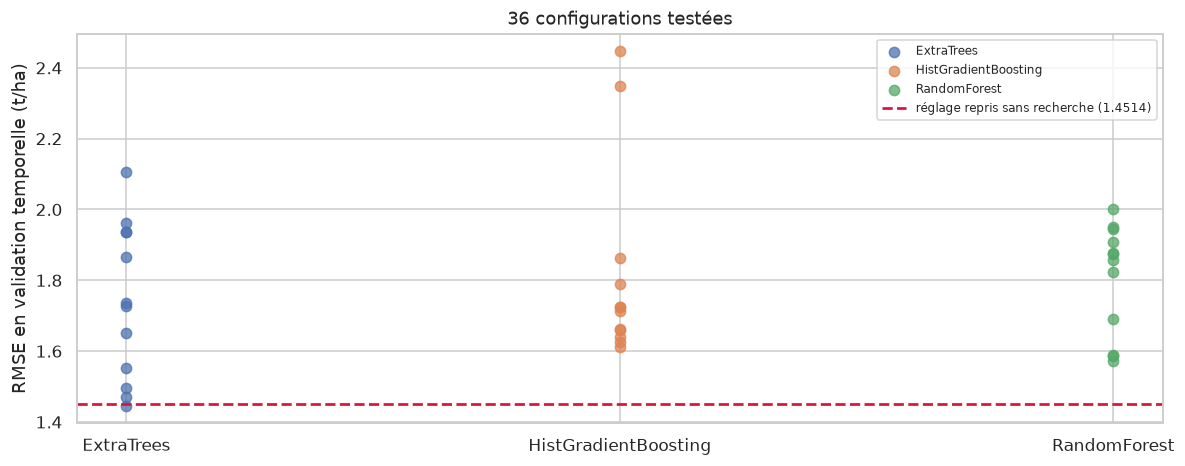

configurations testées                : 36
configurations battant la référence   : 1

meilleure : ExtraTrees, RMSE 1.4458 t/ha (-0.0056 t/ha)


In [14]:
fig, ax = plt.subplots(figsize=(11, 4.4))
for i, (nom, bloc) in enumerate(configurations.groupby("famille")):
    ax.scatter([i] * len(bloc), bloc["rmse"], s=45, alpha=0.75, label=nom)
ax.axhline(rmse_reference, c="crimson", ls="--", lw=1.8,
           label=f"réglage repris sans recherche ({rmse_reference:.4f})")
ax.set_xticks(range(configurations["famille"].nunique()))
ax.set_xticklabels(sorted(configurations["famille"].unique()))
ax.set_ylabel("RMSE en validation temporelle (t/ha)")
ax.set_title(f"{len(configurations)} configurations testées")
ax.legend(fontsize=8)
utils.enregistre("09_optimisation_recommend")
plt.show()

gagnantes = (configurations["rmse"] < rmse_reference).sum()
print(f"configurations testées                : {len(configurations)}")
print(f"configurations battant la référence   : {gagnantes}")
meilleure = configurations.loc[configurations["rmse"].idxmin()]
print()
print(f"meilleure : {meilleure['famille']}, RMSE {meilleure['rmse']:.4f} t/ha "
      f"({meilleure['rmse'] - rmse_reference:+.4f} t/ha)")

In [15]:
# Paired comparison, fold by fold, of the best configurations.
candidats = {"référence (sans recherche)": reference_plis}
for nom, params in meilleurs.items():
    estimateur = GRILLES[nom][0].__class__(
        **{**GRILLES[nom][0].get_params(), **params})
    candidats[f"{nom} optimisé"] = evaluation.validation_par_pli(
        rm.pipeline(estimateur), df[rm.VARIABLES], df[features.CIBLE_RECOMMEND], plis)

evaluation.compare_appariee(candidats, reference="référence (sans recherche)",
                            libelles=rm.ANNEES_VALIDATION).round(4)

,RMSE,MAE,R2,ecart a la reference,plis ameliores,2008,2009,2010,2011,2012
référence (sans recherche),1.4514,0.7252,0.9705,0.0000,0/5,1.2286,1.4768,1.3919,1.5799,1.5798
ExtraTrees optimisé,1.4458,0.7187,0.9707,-0.0056,3/5,1.2089,1.4533,1.3896,1.5891,1.5880
RandomForest optimisé,1.5719,0.8017,0.9653,0.1205,0/5,1.3787,1.7487,1.4506,1.6944,1.5871
HistGradientBoosting optimisé,1.6123,0.8124,0.9635,0.1609,0/5,1.3227,1.7376,1.5699,1.7627,1.6688


In [16]:
# Is the best configuration servable? The setting affects tree size,
# hence file size: performance AND size must be compared.
from sklearn.ensemble import ExtraTreesRegressor

def extra_trees(**kw):
    return rm.pipeline(ExtraTreesRegressor(random_state=config.SEED, n_jobs=1, **kw))

servables = {
    "référence 150 (split=3)": extra_trees(
        n_estimators=150, max_features=0.9, min_samples_split=3),
    "optimisé 150 (split=2)": extra_trees(
        n_estimators=150, max_features=0.9, min_samples_split=2, min_samples_leaf=1),
    "optimisé 300": extra_trees(
        n_estimators=300, max_features=0.9, min_samples_split=2, min_samples_leaf=1),
}
plis_servables = {n: evaluation.validation_par_pli(
    m, df[rm.VARIABLES], df[features.CIBLE_RECOMMEND], plis) for n, m in servables.items()}

comparaison = evaluation.compare_appariee(
    plis_servables, reference="référence 150 (split=3)", libelles=rm.ANNEES_VALIDATION)

X_app_t, _, y_app_t, _ = protocole.decoupage_temporel(
    df, rm.VARIABLES, features.CIBLE_RECOMMEND)
comparaison["taille lzma (Mo)"] = [
    rm.taille_compressee(m.fit(X_app_t, y_app_t)) for m in servables.values()]
comparaison.round(4)

,RMSE,MAE,R2,ecart a la reference,plis ameliores,2008,2009,2010,2011,2012,taille lzma (Mo)
référence 150 (split=3),1.4514,0.7252,0.9705,0.0000,0/5,1.2286,1.4768,1.3919,1.5799,1.5798,38.9835
optimisé 150 (split=2),1.4502,0.7192,0.9705,-0.0012,2/5,1.2075,1.4567,1.3939,1.5924,1.6006,50.4364
optimisé 300,1.4458,0.7187,0.9707,-0.0056,3/5,1.2089,1.4533,1.3896,1.5891,1.5880,100.7344


In [17]:
ecart_type_plis = plis_servables["référence 150 (split=3)"]["rmse"].std()
gain = (plis_servables["référence 150 (split=3)"]["rmse"].mean()
        - plis_servables["optimisé 300"]["rmse"].mean())
print(f"meilleur gain trouvé par la recherche : {gain:.4f} t/ha")
print(f"écart-type entre années de validation : {ecart_type_plis:.4f} t/ha")
print(f"-> le gain est {ecart_type_plis / gain:.0f} fois plus petit que la variation "
      "d'une année à l'autre")

meilleur gain trouvé par la recherche : 0.0056 t/ha
écart-type entre années de validation : 0.1473 t/ha
-> le gain est 26 fois plus petit que la variation d'une année à l'autre


**Observations — la recherche ne livre rien d'utilisable, et il faut le dire ainsi :**

| Configuration | RMSE | Plis améliorés | Taille |
|---|---|---|---|
| référence, reprise sans recherche | 1,4514 | — | **39,0 Mo** |
| meilleure à 150 arbres | 1,4502 | **2/5** | 50,4 Mo |
| meilleure toutes tailles (300 arbres) | 1,4458 | **3/5** | 100,7 Mo |

**Une seule des 36 configurations testées bat le réglage initial.** Celui-ci se situait donc
déjà dans les 3 % supérieurs de l'espace de recherche — il n'était pas arbitraire, mais rien
ne le prouvait avant cette vérification.

Trois raisons de **conserver le réglage initial** :

1. **Le gain est négligeable** : au mieux 0,0056 t/ha, quand l'erreur varie de 0,147 t/ha
   d'une année de validation à l'autre. Le gain est **26 fois plus petit** que cette
   variation : il n'est pas distinguable du bruit d'échantillonnage.
2. **Il ne tient pas pli par pli** : 2 plis sur 5 pour la version à 150 arbres, 3 sur 5
   pour celle à 300. C'est le critère posé plus haut — un gain qui ne tient pas sur une
   majorité d'années n'est pas un gain.
3. **Les deux configurations « meilleures » dépassent la limite de 50 Mo.** Et la raison
   est mécanique : `min_samples_split=2` et `min_samples_leaf=1` laissent les arbres
   pousser plus profond, ce qui alourdit le fichier de 29 % à 158 %. Le réglage initial,
   légèrement plus contraint, produit des arbres plus courts — d'où à la fois sa taille
   réduite et sa performance équivalente.

Ce qui change malgré tout : **le réglage servi est désormais un choix mesuré, non un
réglage hérité.** Il était repris de la littérature sans vérification ; la recherche
confirme qu'il est au niveau du meilleur trouvé, et qu'il est le seul à tenir dans la
contrainte de livraison.

- Les familles restent dans le même ordre qu'avant optimisation (ExtraTrees 1,45 <
  RandomForest 1,57 < HistGradientBoosting 1,61) : le réglage déplace les scores de
  quelques millièmes, il ne renverse pas la hiérarchie.

Le réglage retenu est inscrit dans `recommend_model.modele_retenu`, de sorte que les
notebooks, le script d'entraînement et l'API partagent exactement la même définition.

# 6. Classer, ce n'est pas prédire

Un R² mesure l'erreur sur le rendement. Mais l'utilisateur ne voit pas un rendement : il
voit un **ordre**. Un modèle peut se tromper de 2 t/ha sur chaque culture tout en les
classant parfaitement, ou être précis en moyenne et proposer un ordre absurde.

Trois mesures, calculées au sein de chaque couple pays-année puis moyennées, et comparées à
une référence naïve : le classement figé par rendement médian mondial.

In [18]:
meilleur = rm.pipeline(ExtraTreesRegressor(
    n_estimators=200, max_features=0.9, min_samples_split=3,
    random_state=config.SEED, n_jobs=1))
predictions = evaluation.predictions_hors_apprentissage(
    meilleur, df[rm.VARIABLES], df[features.CIBLE_RECOMMEND], plis)
evalues = df.loc[predictions.index]

# Naive baseline: the same order everywhere, by median yield learned from the past.
medianes = df[df.year < min(rm.ANNEES_VALIDATION)].groupby("crop")["yield_t_ha"].median()
naif = evalues["crop"].map(medianes)

qualite = pd.DataFrame({
    "ExtraTrees": evaluation.qualite_classement(evalues, predictions),
    "classement figé (référence)": evaluation.qualite_classement(evalues, naif),
}).T
qualite.round(4)

,top1,top3,spearman,regret,regret_relatif,groupes
ExtraTrees,0.9339,0.9983,0.9635,0.1062,0.0082,575.0
classement figé (référence),0.7443,0.9635,0.8466,1.3773,0.0856,575.0


**Observations :**

- Le modèle **retrouve très souvent la meilleure culture réellement observée**, et presque
  toujours dans ses trois premières propositions.
- La corrélation de rang est élevée : l'ordre proposé suit de près l'ordre observé.
- Mais la **référence figée fait déjà bien**, parce que l'écart de niveau entre cultures est
  énorme et stable : un tubercule rend structurellement plus qu'une céréale. Le gain du
  modèle porte sur les cas où l'ordre dépend du contexte, pas sur l'ordre général.

> Ce dernier point annonce le problème traité au notebook 10 : classer en tonnes brutes
> revient en grande partie à réciter la hiérarchie tubercules / céréales.

**Portée de ces chiffres.** Ils mesurent l'ordre **en tonnes brutes, sur les dix cultures
FAO** : c'est le bon critère pour choisir un modèle, pas la qualité de ce que verra
l'utilisateur. Le classement servi — en matière sèche ou en produit brut, sur les quatre
cultures de l'application — est mesuré pour lui-même au notebook 10.

In [19]:
# Where does the model go wrong? Relative error makes crops comparable.
evaluation.erreurs_par_culture(
    evalues[features.CIBLE_RECOMMEND], predictions, evalues["crop"]).round(3)

,n,rendement moyen,RMSE,MAE,biais,RMSE relative
culture,,,,,,
Soybeans,360,1.732,0.325,0.221,-0.024,0.187
Sorghum,380,2.040,0.925,0.381,-0.041,0.453
Wheat,456,3.347,0.533,0.363,-0.057,0.159
"Rice, paddy",395,4.309,0.546,0.372,-0.139,0.127
Maize,533,4.531,0.794,0.488,-0.139,0.175
Plantains and others,133,10.108,1.649,0.835,-0.076,0.163
Yams,120,10.746,1.248,0.762,-0.091,0.116
Cassava,245,11.754,2.164,1.234,-0.291,0.184
Sweet potatoes,300,11.882,2.453,1.177,-0.513,0.206


**Observations :** la RMSE brute suit mécaniquement le niveau de rendement — 2 t/ha d'erreur
sur la pomme de terre et sur le sorgho n'ont pas le même sens. La **RMSE relative** corrige
cette lecture : rapportée au rendement moyen, l'erreur est du même ordre pour la plupart des
cultures, et les plus mal prédites sont celles qui ont le moins d'observations.

# Conclusion

## Le protocole, qui est le résultat principal
Le rendement est corrélé à **0,985** d'une année sur l'autre. Un découpage aléatoire place
donc des lignes quasi identiques des deux côtés et **surestime fortement la performance**.
Toute l'évaluation est faite en **découpage temporel** : apprendre sur le passé, prédire
l'année suivante. 2013 n'a servi à aucun choix.

## Les variables
- `year` est **indispensable** : elle porte la tendance technologique.
- Le **code pays** apporte, mais il est remplacé par la **position géographique** : même
  nature d'information, sans identifiant, et partagée entre pays voisins.
- Les conditions sont prises sur les **trois années précédentes**, seules connues au moment
  de recommander. On y perd très peu.

## Le modèle
**`ExtraTrees`**, meilleur sur les cinq années de validation, et deux à trois fois meilleur
que la régression linéaire — à l'inverse de `/predict`.

## Ce qui reste à traiter
Le classement en tonnes brutes reproduit surtout la hiérarchie tubercules / céréales : il
placerait un tubercule en tête presque partout. C'est l'objet du notebook 10, avec la taille
du modèle servi et l'évaluation finale sur 2013.